#**Практическое задание №1**

Установка необходимых пакетов:

In [ ]:
!pip install -q tqdm
!pip install --upgrade --no-cache-dir gdown

Монтирование Вашего Google Drive к текущему окружению:

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Константы, которые пригодятся в коде далее, и ссылки (gdrive идентификаторы) на предоставляемые наборы данных:

In [ ]:
EVALUATE_ONLY = True
TEST_ON_LARGE_DATASET = True
TISSUE_CLASSES = ('ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM')
DATASETS_LINKS = {
    'train': '1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi',
    'train_small': '1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR',
    'train_tiny': '1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui',
    'test': '1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr',
    'test_small': '1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI',
    'test_tiny': '1viiB0s041CNsAK4itvX8PnYthJ-MDnQc'
}


Импорт необходимых зависимостей:

In [ ]:
from pathlib import Path
import numpy as np
from typing import List
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from time import sleep
from PIL import Image
import IPython.display
from sklearn import metrics
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay
import gdown

import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset as TorchDataset, DataLoader, Subset, random_split
import torchvision.transforms as T

seed = 42
def set_seed(seed = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство обучения:", device)
if device.type == "cuda":
    print("Используется следующая видеокарта:", torch.cuda.get_device_name(0))

Устройство обучения: cuda
Используется следующая видеокарта: Tesla T4


---
### Класс Dataset

Предназначен для работы с наборами данных, обеспечивает чтение изображений и соответствующих меток, а также формирование пакетов (батчей).

In [ ]:
class Dataset:

    def __init__(self, name):
        self.name = name
        self.is_loaded = False
        url = f"https://drive.google.com/uc?export=download&confirm=pbef&id={DATASETS_LINKS[name]}"
        output = f'{name}.npz'
        gdown.download(url, output, quiet=False)
        print(f'Loading dataset {self.name} from npz.')
        np_obj = np.load(f'{name}.npz')
        self.images = np_obj['data']
        self.labels = np_obj['labels']
        self.n_files = self.images.shape[0]
        self.is_loaded = True
        print(f'Done. Dataset {name} consists of {self.n_files} images.')

    def image(self, i):
        # read i-th image in dataset and return it as numpy array
        if self.is_loaded:
            return self.images[i, :, :, :]

    def images_seq(self, n=None):
        # sequential access to images inside dataset (is needed for testing)
        for i in range(self.n_files if not n else n):
            yield self.image(i)

    def random_image_with_label(self):
        # get random image with label from dataset
        i = np.random.randint(self.n_files)
        return self.image(i), self.labels[i]

    def random_batch_with_labels(self, n):
        # create random batch of images with labels (is needed for training)
        indices = np.random.choice(self.n_files, n)
        imgs = [self.image(i) for i in indices]
        labels = np.array([self.labels[i] for i in indices])
        return np.stack(imgs), labels

    def image_with_label(self, i: int):
        # return i-th image with label from dataset
        return self.image(i), self.labels[i]


### Пример использвания класса Dataset
Загрузим обучающий набор данных, получим произвольное изображение с меткой. После чего визуализируем изображение, выведем метку. В будущем, этот кусок кода можно закомментировать или убрать.

Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=0a8703aa-5d83-4688-ab41-2f1e1d63731e
To: /content/train_tiny.npz
100%|██████████| 105M/105M [00:01<00:00, 69.6MB/s] 


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.

Got numpy array of shape (224, 224, 3), and label with code 7.
Label code corresponds to STR class.


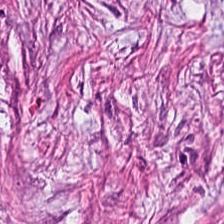

In [ ]:
d_train_tiny = Dataset('train_tiny')

img, lbl = d_train_tiny.random_image_with_label()
print()
print(f'Got numpy array of shape {img.shape}, and label with code {lbl}.')
print(f'Label code corresponds to {TISSUE_CLASSES[lbl]} class.')

pil_img = Image.fromarray(img)
IPython.display.display(pil_img)

### Обёртка над Dataset для использования с PyTorch

In [ ]:
# ============================================================
# (Опционально) Обёртка над Dataset для использования с PyTorch
# ============================================================

# ВНИМАНИЕ:
# Этот код нужен только тем, кто хочет решать задание с помощью PyTorch.
# Он показывает, как "подключить" наш Dataset к torch.utils.data.DataLoader.

try:
    import torch
    from torch.utils.data import Dataset as TorchDataset, DataLoader
    import torchvision.transforms as T
    from PIL import Image

    class HistologyTorchDataset(TorchDataset):
        """
        Обёртка над Dataset для использования с PyTorch.

        base_dataset: экземпляр Dataset('train'), Dataset('train_small'), etc.
        transform:    функция/объект, преобразующий изображение (PIL.Image -> torch.Tensor).

        """
        def __init__(self, base_dataset, transform=None):
            self.base = base_dataset
            # Минимальный transform по умолчанию:
            # np.uint8 [0, 255] -> float32 [0.0, 1.0]
            self.transform = transform or T.ToTensor()

        def __len__(self):
            # Размер датасета
            return len(self.base.images)

        def __getitem__(self, idx):
            """
            Возвращает (image_tensor, label) для PyTorch.
            image_tensor: torch.Tensor формы [3, H, W]
            label: int
            """
            img, label = self.base.image_with_label(idx)  # img: np.ndarray (H, W, 3)
            img = Image.fromarray(img)                    # в PIL.Image
            img = self.transform(img)                     # в torch.Tensor
            return img, int(label)

except ImportError:
    HistologyTorchDataset = None
    print("PyTorch / torchvision не найдены. Обёртка HistologyTorchDataset недоступна.")


### Пример использвания класса HistologyTorchDataset

In [ ]:
if "HistologyTorchDataset" not in globals() or HistologyTorchDataset is None:
    print("PyTorch не установлен или обёртка недоступна — пример пропущен.")
else:
    print("Пример использования PyTorch-обёртки над Dataset")

    base_train = Dataset('train_tiny')

    # Создаём PyTorch-совместимый датасет
    train_ds = HistologyTorchDataset(base_train)

    # DataLoader автоматически создаёт батчи и перемешивает данные
    from torch.utils.data import DataLoader
    train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)

    # Берём один батч и выводим информацию
    images_batch, labels_batch = next(iter(train_loader))

    print("Форма батча изображений:", tuple(images_batch.shape))  # [batch, 3, 224, 224]
    print("Форма батча меток:", tuple(labels_batch.shape))        # [batch]
    print("Пример меток:", labels_batch[:10].tolist())

    print("Тип images_batch:", type(images_batch))
    print("Тип labels_batch:", type(labels_batch))


Пример использования PyTorch-обёртки над Dataset


Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=ef3484f6-45b2-47eb-a18f-a255ec5a1626
To: /content/train_tiny.npz
100%|██████████| 105M/105M [00:00<00:00, 107MB/s]


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.
Форма батча изображений: (8, 3, 224, 224)
Форма батча меток: (8,)
Пример меток: [3, 0, 2, 2, 3, 8, 4, 7]
Тип images_batch: <class 'torch.Tensor'>
Тип labels_batch: <class 'torch.Tensor'>


---
### Класс Metrics

Реализует метрики точности, используемые для оценивания модели:
1. точность,
2. сбалансированную точность.

In [ ]:
class Metrics:

    @staticmethod
    def accuracy(gt: List[int], pred: List[int]):
        assert len(gt) == len(pred), 'gt and prediction should be of equal length'
        return sum(int(i[0] == i[1]) for i in zip(gt, pred)) / len(gt)

    @staticmethod
    def accuracy_balanced(gt: List[int], pred: List[int]):
        return balanced_accuracy_score(gt, pred)

    @staticmethod
    def print_all(gt: List[int], pred: List[int], info: str):
        print(f'metrics for {info}:')
        print('\t accuracy {:.4f}:'.format(Metrics.accuracy(gt, pred)))
        print('\t balanced accuracy {:.4f}:'.format(Metrics.accuracy_balanced(gt, pred)))

---
### Класс Model

Класс, хранящий в себе всю информацию о модели.

Вам необходимо реализовать методы save, load для сохранения и загрузки модели. Особенно актуально это будет во время тестирования на дополнительных наборах данных.


> *Пожалуйста, убедитесь, что сохранение и загрузка модели работает корректно. Для этого обучите модель, протестируйте, сохраните ее в файл, перезапустите среду выполнения, загрузите обученную модель из файла, вновь протестируйте ее на тестовой выборке и убедитесь в том, что получаемые метрики совпадают с полученными для тестовой выборки ранее.*


Также, Вы можете реализовать дополнительные функции, такие как:
1. валидацию модели на части обучающей выборки;
2. использование кроссвалидации;
3. автоматическое сохранение модели при обучении;
4. загрузку модели с какой-то конкретной итерации обучения (если используется итеративное обучение);
5. вывод различных показателей в процессе обучения (например, значение функции потерь на каждой эпохе);
6. построение графиков, визуализирующих процесс обучения (например, график зависимости функции потерь от номера эпохи обучения);
7. автоматическое тестирование на тестовом наборе/наборах данных после каждой эпохи обучения (при использовании итеративного обучения);
8. автоматический выбор гиперпараметров модели во время обучения;
9. сохранение и визуализацию результатов тестирования;
10. Использование аугментации и других способов синтетического расширения набора данных (дополнительным плюсом будет обоснование необходимости и обоснование выбора конкретных типов аугментации)
11. и т.д.

Полный список опций и дополнений приведен в презентации с описанием задания.

При реализации дополнительных функций допускается добавление параметров в существующие методы и добавление новых методов в класс модели.


In [ ]:
class BaseClassifier(nn.Module):
    """
    #LBL1
    Простой классификатор с настроенным пайплайном
    """

    def __init__(self, num_classes = len(TISSUE_CLASSES)):
        super().__init__()
        self.num_classes = num_classes
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.history = {}
        self.to(self.device)
    #LBL2
    def _run_epoch(self, loader, criterion, optimizer = None):
        is_training = optimizer is not None
        self.train(is_training)
        total_loss = 0.0
        total_correct = 0
        total_count = 0

        for images, labels in loader:
            images = images.to(self.device, non_blocking = True)
            labels = labels.to(self.device, dtype=torch.long, non_blocking=True)

            if is_training: #обнуляем градиент для каждого батча
                optimizer.zero_grad(set_to_none=True)

            with torch.set_grad_enabled(is_training):
                logits = self(images) #запуск расчета логитов
                loss = criterion(logits, labels)
                if is_training:
                    loss.backward()
                    optimizer.step()
            batch_size = labels.size(0)
            total_loss += loss.item()*batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_count += batch_size
        epoch_loss = total_loss / total_count
        epoch_accuracy = total_correct / total_count
        return epoch_loss, epoch_accuracy

    #LBL3
    def _fit(self, train_loader: DataLoader, val_loader: DataLoader, optimizer,
             criterion, epochs, scheduler=None, patience=None):
        #намеренно переимовал train на fit иначе был бы конфликт имен с методом train из pytorch
        history = {
            "train_loss": [],
            "val_loss": [],
            "train_accuracy": [],
            "val_accuracy": [],
            "learning_rate": [],
        }
        best_val_loss = float("inf")
        best_state = None
        best_epoch = 0
        epochs_without_improvement = 0

        print(f"Обучение на устройстве: {self.device}")

        for epoch in range(epochs):
            train_loss, train_accuracy = self._run_epoch(train_loader, criterion, optimizer)
            val_loss, val_accuracy = self._run_epoch(val_loader, criterion, optimizer=None)

            if scheduler is not None:
                scheduler.step(val_loss) #передаем планировщику потери

            current_lr = optimizer.param_groups[0]["lr"] #запомнинаем текущую lr что корректировать её в процессе обучения
            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_accuracy"].append(train_accuracy)
            history["val_accuracy"].append(val_accuracy)
            history["learning_rate"].append(current_lr)
            print(
                f"Эпоха {epoch}/{epochs} | "
                f"train loss: {train_loss:.4f} | "
                f"val loss: {val_loss:.4f} | "
                f"train acc: {train_accuracy:.4f} | "
                f"val acc: {val_accuracy:.4f} | "
                f"lr: {current_lr:.6f}"
            )
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_epoch = epoch + 1
                best_state = {} #словарь для сохранения лучших параметров
                for key, value in self.state_dict().items():
                    value = value.detach().cpu().clone()
                    best_state[key] = value
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
            if patience is not None and epochs_without_improvement >= patience:
                print("Модель перестала обучаться, досрочное завершение")
                break
        if best_state is not None:
            self.load_state_dict(best_state)
        history["best_epoch"] = best_epoch
        self.history = history
        self.eval()
        print(f"Обучение завершено. Лучшая эпоха: {best_epoch}.")
        return history

    def save(self, name: str):
        # todo: сохраните веса вашей модели.
        # Пример уже рабочий: он пишет npz на Google Drive, а load читает тот же файл.
        path = f'/content/drive/MyDrive/{name}.pth'
        torch.save(self.state_dict(), path)
        print(f'Модель сохранена в {path}.')
        #print('Чтобы сдать файл ссылкой, откройте к нему доступ и вставьте id в load().')

    def load(self, name: str):
        # todo: если сдаёте модель ссылкой, замените None на id вашего файла.
        # Пока id не указан, читаетсагя файл, который save записал на примонтированный Drive.
        name_to_id_dict = {
            'best': "1TpWZyzKipzBZv-XUgmTBjv2JdjZp3mcQ",
            'baseline': "1bzczlNWmt04c0Rmek2l6gpDqfWqt_pLk" #здесь хранятся тестовой базовой модели
        }
        file_id = name_to_id_dict.get(name)
        if file_id:
            path = Path(f"/content/{name}.pth")
            gdown.download(id=file_id, output=str(path), quiet=False)
        else:
            path = Path(f'/content/drive/MyDrive/{name}.pth')
        if not path.exists():
            raise FileNotFoundError(
                f'Не найден {path}. Вызовите save("{name}") при смонтированном Google Drive '
                f'или укажите id файла в name_to_id_dict внутри load().'
            )
        state_dict = torch.load(path, map_location=self.device)
        self.load_state_dict(state_dict)
        self.to(self.device)
        self.eval()
        print(f"Веса модели загружены из {path}")

    #LBL4
    def test_on_dataset(self, dataset: Dataset, limit=None, seed=42):
        predictions = []
        n = dataset.n_files if not limit else int(dataset.n_files * limit)
        test_ds = HistologyTorchDataset(dataset, transform=T.ToTensor())
        generator = torch.Generator().manual_seed(seed)
        shuffled_indices = torch.randperm(len(test_ds), generator=generator)[:n].tolist()
        test_ds = Subset(test_ds, shuffled_indices) #создаем подмножество датасета
        test_loader = DataLoader(
            test_ds,
            batch_size = 64,
            shuffle=False,
            pin_memory=(self.device.type == "cuda")
            #используем специальную область озу для ускорения передачи
            #данных с озу на gpu
        )
        self.eval()
        with torch.inference_mode():
            for images, _labels in tqdm(test_loader, total=len(test_loader)):
                images = images.to(self.device, non_blocking=True)
                logits = self(images)
                predictions.extend(logits.argmax(dim=1).cpu().tolist())

        return predictions, shuffled_indices

    #LBL5
    def test_on_image(self, img: np.ndarray, submission_year: int):
        image = Image.fromarray(img)
        image_tensor = T.ToTensor()(image).unsqueeze(0).to(self.device)
        self.eval()
        with torch.inference_mode():
            logits = self(image_tensor)
            prediction = int(logits.argmax(dim=1).item())

        return prediction


In [ ]:
class BaselineModel(BaseClassifier):
    """
    Самая простая CNN с полным пайплайном
    """
    def __init__(self, num_classes=len(TISSUE_CLASSES)):
        super().__init__(num_classes)
        self.conv1 = nn.Conv2d(3, 6, kernel_size=5)
        self.pool = nn.MaxPool2d(kernel_size=4, stride=4)
        self.conv2 = nn.Conv2d(6, 12, kernel_size=5)
        # Для входа 224x224:
        # 224 -> conv1: 220 -> pool: 55 -> conv2: 51 -> pool: 12.
        self.fc1 = nn.Linear(12 * 12 * 12, num_classes)
        self.to(self.device)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.flatten(1)
        return self.fc1(x)
    #LBL6
    def fit(self, dataset, epochs=10, batch_size=32, lr=1e-3, val_split=0.2, patience=4):
        set_seed(seed)
        full_ds = HistologyTorchDataset(dataset, transform=T.ToTensor())
        val_size = int(len(full_ds) * val_split)
        train_size = len(full_ds) - val_size
        train_ds, val_ds = random_split(
            full_ds,
            [train_size, val_size],
            generator=torch.Generator().manual_seed(seed)
        )

        train_loader = DataLoader(
            train_ds,
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(seed),
            pin_memory=(self.device.type == 'cuda'),
        )
        val_loader = DataLoader(
            val_ds,
            batch_size=batch_size,
            shuffle=False,
            pin_memory=(self.device.type == 'cuda'),
        )
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.SGD(
            self.parameters(),
            lr=lr,
            momentum=0.9
        )

        return self._fit(
            train_loader, val_loader, optimizer, criterion,
            epochs=epochs, scheduler=None, patience=patience
        )


In [ ]:
#LBL7
class RandomQuarterTurn:
    """Случайный поворот тензора
        на 0, 90, 180 или 270 градусов
    """

    def __call__(self, image):
        k = int(torch.randint(0, 4, (1,)).item())

        return torch.rot90(
            image,
            k=k,
            dims=(-2, -1)
        ).contiguous()

In [ ]:
class Model(BaseClassifier):
    """
    Улучшенная модель:
    1. Больше сверточных фильтров
    2. Использование BatchNorm
    3. Dropout для уменьшения переобучения
    """
    #LBL8
    def __init__(self, num_classes=len(TISSUE_CLASSES)):
        super().__init__(num_classes)
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, stride=2, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((4, 4)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128*4*4, num_classes)
        )
        self.to(self.device)

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

    def fit(self, dataset: Dataset, epochs=20, batch_size=32,
            lr=3e-4, weight_decay=1e-4, val_split=0.2, patience=5):
        """
        Использовал аугментацию
        Использование оптимизатора AdamW и L2 регуляризации
        Динамическое изменение lr с помощью scheduler
        Досрочное завершение обучения при отсутвии прогресса
        """
        set_seed(seed)
        train_transform = T.Compose([
            T.ToTensor(),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomVerticalFlip(p=0.5),

            RandomQuarterTurn(),
        ])
        val_transform = T.ToTensor()

        indices = torch.randperm( #рандомно перемешиваем индексы
            len(dataset.images),
            generator=torch.Generator().manual_seed(seed)
        ).tolist()

        val_size = int(len(indices) * val_split)
        train_indices = indices[val_size:]
        val_indices = indices[:val_size]

        train_base = HistologyTorchDataset(dataset, transform=train_transform)
        val_base = HistologyTorchDataset(dataset, transform=val_transform)

        train_ds = Subset(train_base, train_indices)
        val_ds = Subset(val_base, val_indices)

        train_loader = DataLoader(
            train_ds,
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(seed),
            pin_memory=(self.device.type == "cuda"),
        )
        val_loader = DataLoader(
            val_ds,
            batch_size=batch_size,
            shuffle=False,
            pin_memory=(self.device.type == "cuda"),
        )

        criterion = nn.CrossEntropyLoss(label_smoothing=0.05) #label_smoothing для смягчения итоговых вероятностей

        optimizer = optim.AdamW(
            self.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
           optimizer,
           mode="min",
           factor=0.5,
           patience=2
        )

        return self._fit(
            train_loader, val_loader, optimizer, criterion,
            epochs, scheduler, patience
        )


---
### Классификация изображений

Используя введенные выше классы можем перейти уже непосредственно к обучению модели классификации изображений. Пример общего пайплайна решения задачи приведен ниже. Вы можете его расширять и улучшать. В данном примере используются наборы данных 'train_small' и 'test_small'.

In [ ]:
d_train = Dataset('train')
d_test = Dataset('test')


Downloading...
From (original): https://drive.google.com/uc?id=1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi
From (redirected): https://drive.google.com/uc?id=1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi&confirm=t&uuid=1de5b998-9d2d-4edc-9660-560e24ad6a84
To: /content/train.npz
100%|██████████| 2.10G/2.10G [00:33<00:00, 62.3MB/s]


Loading dataset train from npz.
Done. Dataset train consists of 18000 images.


Downloading...
From (original): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr
From (redirected): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr&confirm=t&uuid=75911695-4bd7-40d1-a64c-6cecae851f77
To: /content/test.npz
100%|██████████| 525M/525M [00:07<00:00, 67.9MB/s]


Loading dataset test from npz.
Done. Dataset test consists of 4500 images.


In [ ]:
#LBL9

set_seed(seed)
baseline_model = BaselineModel()

if not EVALUATE_ONLY:
    baseline_history = baseline_model.fit(
        d_train,
        epochs=10,
        batch_size=32,
        lr=1e-3,
        val_split=0.2,
        patience=4,
    )

    baseline_model.save('baseline')

else:
    baseline_model.load('baseline')

Обучение на устройстве: cuda
Эпоха 0/10 | train loss: 2.1628 | val loss: 2.0964 | train acc: 0.1744 | val acc: 0.2933 | lr: 0.001000
Эпоха 1/10 | train loss: 1.7397 | val loss: 1.3647 | train acc: 0.3658 | val acc: 0.4689 | lr: 0.001000
Эпоха 2/10 | train loss: 1.2703 | val loss: 1.2027 | train acc: 0.5112 | val acc: 0.5469 | lr: 0.001000
Эпоха 3/10 | train loss: 1.1464 | val loss: 1.3359 | train acc: 0.5622 | val acc: 0.5033 | lr: 0.001000
Эпоха 4/10 | train loss: 1.0886 | val loss: 1.0441 | train acc: 0.5878 | val acc: 0.6156 | lr: 0.001000
Эпоха 5/10 | train loss: 1.0111 | val loss: 1.0390 | train acc: 0.6240 | val acc: 0.5967 | lr: 0.001000
Эпоха 6/10 | train loss: 0.9391 | val loss: 0.9155 | train acc: 0.6560 | val acc: 0.6739 | lr: 0.001000
Эпоха 7/10 | train loss: 0.8672 | val loss: 0.8292 | train acc: 0.6874 | val acc: 0.7039 | lr: 0.001000
Эпоха 8/10 | train loss: 0.8181 | val loss: 0.8849 | train acc: 0.7059 | val acc: 0.6892 | lr: 0.001000
Эпоха 9/10 | train loss: 0.7697 | v

Пример тестирования модели на части набора данных:

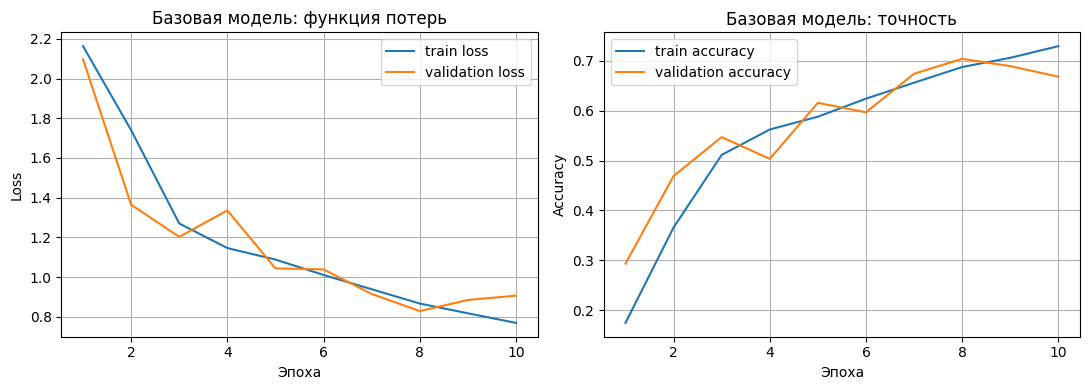

In [ ]:
#LBL10
if not EVALUATE_ONLY:
    epochs_axis = range(1, len(baseline_history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs_axis, baseline_history["train_loss"], label="train loss")
    axes[0].plot(epochs_axis, baseline_history["val_loss"], label="validation loss")
    axes[0].set_title("Базовая модель: функция потерь")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs_axis, baseline_history["train_accuracy"], label="train accuracy")
    axes[1].plot(epochs_axis, baseline_history["val_accuracy"], label="validation accuracy")
    axes[1].set_title("Базовая модель: точность")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("Графики обучения появятся только после запуска обучения с EVALUATE_ONLY=False.")

In [ ]:
#LBL11
pred_1, test_indices = baseline_model.test_on_dataset(d_test, limit=0.2, seed=seed)
true_labels = np.asarray(d_test.labels)[test_indices]
Metrics.print_all(
    true_labels.tolist(),
    pred_1,
    'baseline: 50% of test'
)

  0%|          | 0/15 [00:00<?, ?it/s]

metrics for baseline: 50% of test:
	 accuracy 0.7244:
	 balanced accuracy 0.7183:


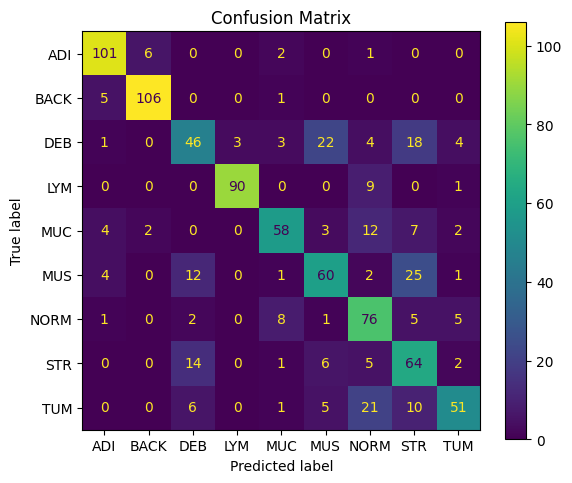

In [ ]:
#LBL12
cm = metrics.confusion_matrix(true_labels.tolist(), pred_1)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=TISSUE_CLASSES)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax)
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

**Запуск и тестирование итоговой модели**

In [ ]:
set_seed(seed)
model = Model()

if not EVALUATE_ONLY:
    improved_history = model.fit(
        d_train,
        epochs=30,
        batch_size=128,
        lr=6e-4,
        weight_decay=1e-4,
        val_split=0.2,
        patience=5,
    )
    model.save('best')
else:
    model.load('best')

Обучение на устройстве: cuda
Эпоха 0/30 | train loss: 1.1091 | val loss: 1.2392 | train acc: 0.6552 | val acc: 0.6358 | lr: 0.000600
Эпоха 1/30 | train loss: 0.8737 | val loss: 1.2223 | train acc: 0.7663 | val acc: 0.6022 | lr: 0.000600
Эпоха 2/30 | train loss: 0.7890 | val loss: 0.7488 | train acc: 0.8042 | val acc: 0.8158 | lr: 0.000600
Эпоха 3/30 | train loss: 0.7193 | val loss: 0.7877 | train acc: 0.8330 | val acc: 0.8178 | lr: 0.000600
Эпоха 4/30 | train loss: 0.6831 | val loss: 0.9499 | train acc: 0.8516 | val acc: 0.7372 | lr: 0.000600
Эпоха 5/30 | train loss: 0.6339 | val loss: 0.9951 | train acc: 0.8731 | val acc: 0.7064 | lr: 0.000300
Эпоха 6/30 | train loss: 0.5834 | val loss: 0.7091 | train acc: 0.8950 | val acc: 0.8347 | lr: 0.000300
Эпоха 7/30 | train loss: 0.5609 | val loss: 0.5216 | train acc: 0.9065 | val acc: 0.9286 | lr: 0.000300
Эпоха 8/30 | train loss: 0.5555 | val loss: 0.6038 | train acc: 0.9101 | val acc: 0.8750 | lr: 0.000300
Эпоха 9/30 | train loss: 0.5416 | v

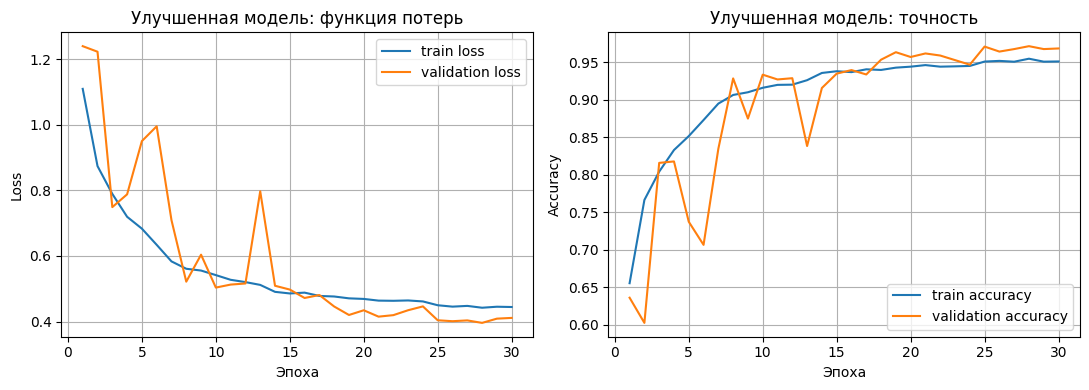

In [ ]:
if not EVALUATE_ONLY:
    epochs_axis = range(1, len(improved_history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs_axis, improved_history["train_loss"], label="train loss")
    axes[0].plot(epochs_axis, improved_history["val_loss"], label="validation loss")
    axes[0].set_title("Улучшенная модель: функция потерь")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs_axis, improved_history["train_accuracy"], label="train accuracy")
    axes[1].plot(epochs_axis, improved_history["val_accuracy"], label="validation accuracy")
    axes[1].set_title("Улучшенная модель: точность")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


Пример тестирования модели на полном наборе данных:

  0%|          | 0/71 [00:00<?, ?it/s]

metrics for model: full test:
	 accuracy 0.9691:
	 balanced accuracy 0.9691:


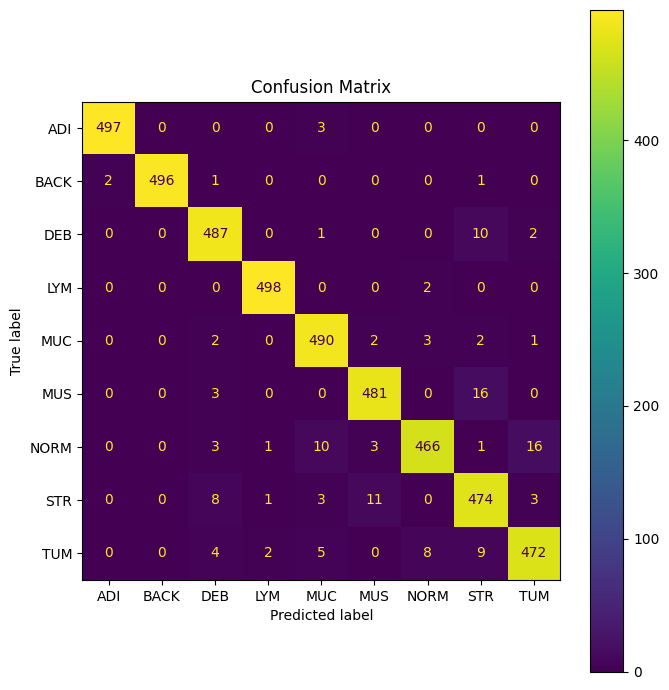

In [ ]:
# evaluating model on full test dataset (may take time)
if TEST_ON_LARGE_DATASET:
    pred_1_improved, test_indices = model.test_on_dataset(d_test, limit=1, seed=seed)
    true_labels = np.asarray(d_test.labels)[test_indices]
    Metrics.print_all(
        true_labels.tolist(),
        pred_1_improved,
        'model: full test'
    )

    cm = metrics.confusion_matrix(true_labels.tolist(), pred_1_improved)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=TISSUE_CLASSES)

    fig, ax = plt.subplots(figsize=(7, 7))
    disp.plot(ax=ax)
    ax.set_title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

Результат предсказания для рандомного изображения

Индекс: 602
Реальный класс: BACK
Предсказанный класс: BACK


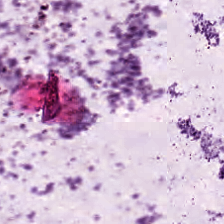

In [ ]:
pos = np.random.randint(len(pred_1_improved))
idx = test_indices[pos]
img = d_test.images[idx]
true_label = int(d_test.labels[idx])
predicted_label = int(pred_1_improved[pos])
true_class = TISSUE_CLASSES[true_label]
predicted_class = TISSUE_CLASSES[predicted_label]
print(f"Индекс: {idx}")
print(f"Реальный класс: {true_class}")
print(f"Предсказанный класс: {predicted_class}")
pil_img = Image.fromarray(img)
IPython.display.display(pil_img)

Результат работы пайплайна обучения и тестирования выше тоже будет оцениваться. Поэтому не забудьте присылать на проверку ноутбук с выполнеными ячейками кода с демонстрациями метрик обучения, графиками и т.п. В этом пайплайне Вам необходимо продемонстрировать работу всех реализованных дополнений, улучшений и т.п.

<font color="red">
Настоятельно рекомендуется после получения пайплайна с полными результатами обучения экспортировать ноутбук в pdf (файл -> печать) и прислать этот pdf вместе с самим ноутбуком.
</font>

### Тестирование модели на других наборах данных

Ваша модель должна поддерживать тестирование на других наборах данных. Для удобства, Вам предоставляется набор данных test_tiny, который представляет собой малую часть (2% изображений) набора test. Ниже приведен фрагмент кода, который будет осуществлять тестирование для оценивания Вашей модели на дополнительных тестовых наборах данных.

<font color="red">
Прежде чем отсылать задание на проверку, убедитесь в работоспособности фрагмента кода ниже.
</font>


Downloading...
From: https://drive.google.com/uc?id=1a8LElUsk00x2KgJm_utLA-Dy7Tur_EGq
To: /content/best.pth
100%|██████████| 606k/606k [00:00<00:00, 113MB/s]


Веса модели загружены из /content/best.pth


Downloading...
From (original): https://drive.google.com/uc?id=1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI
From (redirected): https://drive.google.com/uc?id=1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI&confirm=t&uuid=661792db-c066-4786-aa98-0a9671d26249
To: /content/test_small.npz
100%|██████████| 211M/211M [00:01<00:00, 156MB/s]


Loading dataset test_small from npz.
Done. Dataset test_small consists of 1800 images.


  0%|          | 0/29 [00:00<?, ?it/s]

metrics for test-small:
	 accuracy 0.9694:
	 balanced accuracy 0.9694:


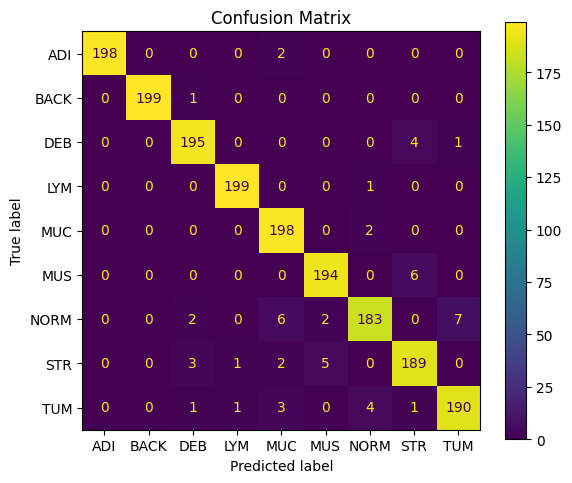

In [ ]:
#LBL13
final_model = Model()
final_model.load('best')
d_test_tiny = Dataset('test_small')
pred, test_indices = final_model.test_on_dataset(d_test_tiny)
true_labels = np.asarray(d_test_tiny.labels)[test_indices]
Metrics.print_all(true_labels.tolist(), pred, 'test-small')


cm = metrics.confusion_matrix(true_labels.tolist(), pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=TISSUE_CLASSES)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax)
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

Google Drive пока не отключаем: примеры архивов ниже пишут файлы на Диск. Отключение стоит в последней ячейке.


In [ ]:
# Диск остаётся примонтированным до последней ячейки.


---
# Дополнительные "полезности"

Ниже приведены примеры использования различных функций и библиотек, которые могут быть полезны при выполнении данного практического задания.

### Измерение времени работы кода

Измерять время работы какой-либо функции можно легко и непринужденно при помощи функции timeit из соответствующего модуля:

In [ ]:
import timeit

def factorial(n):
    res = 1
    for i in range(1, n + 1):
        res *= i
    return res


def f():
    return factorial(n=1000)

n_runs = 128
print(f'Function f is caluclated {n_runs} times in {timeit.timeit(f, number=n_runs)}s.')

### Scikit-learn

Для использования "классических" алгоритмов машинного обучения рекомендуется использовать библиотеку scikit-learn (https://scikit-learn.org/stable/). Пример классификации изображений цифр из набора данных MNIST при помощи классификатора SVM:

In [ ]:
# Standard scientific Python imports
import matplotlib.pyplot as plt

# Import datasets, classifiers and performance metrics
from sklearn import datasets, svm, metrics
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# The digits dataset
digits = datasets.load_digits()

# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the
# dataset.  If we were working from image files, we could load them using
# matplotlib.pyplot.imread.  Note that each image must have the same size. For these
# images, we know which digit they represent: it is given in the 'target' of
# the dataset.
_, axes = plt.subplots(2, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes[0, :], images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)

# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# Create a classifier: a support vector classifier
classifier = svm.SVC(gamma=0.001)

# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.5, shuffle=False)

# We learn the digits on the first half of the digits
classifier.fit(X_train, y_train)

# Now predict the value of the digit on the second half:
predicted = classifier.predict(X_test)

images_and_predictions = list(zip(digits.images[n_samples // 2:], predicted))
for ax, (image, prediction) in zip(axes[1, :], images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)

print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))

# Матрица ошибок + визуализация в новом API
cm = metrics.confusion_matrix(y_test, predicted)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=classifier.classes_)

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax)
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

### Scikit-image

Реализовывать различные операции для работы с изображениями можно как самостоятельно, работая с массивами numpy, так и используя специализированные библиотеки, например, scikit-image (https://scikit-image.org/). Ниже приведен пример использования Canny edge detector.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from skimage import feature


# Generate noisy image of a square
im = np.zeros((128, 128))
im[32:-32, 32:-32] = 1

im = ndi.rotate(im, 15, mode='constant')
im = ndi.gaussian_filter(im, 4)
im += 0.2 * np.random.random(im.shape)

# Compute the Canny filter for two values of sigma
edges1 = feature.canny(im)
edges2 = feature.canny(im, sigma=3)

# display results
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(8, 3),
                                    sharex=True, sharey=True)

ax1.imshow(im, cmap=plt.cm.gray)
ax1.axis('off')
ax1.set_title('noisy image', fontsize=20)

ax2.imshow(edges1, cmap=plt.cm.gray)
ax2.axis('off')
ax2.set_title(r'Canny filter, $\sigma=1$', fontsize=20)

ax3.imshow(edges2, cmap=plt.cm.gray)
ax3.axis('off')
ax3.set_title(r'Canny filter, $\sigma=3$', fontsize=20)

fig.tight_layout()

plt.show()

### Tensorflow 2

Для создания и обучения нейросетевых моделей можно использовать фреймворк глубокого обучения Tensorflow 2. Ниже приведен пример простейшей нейроной сети, использующейся для классификации изображений из набора данных MNIST.

In [ ]:
# Install TensorFlow

import tensorflow as tf

mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

demo_mnist_model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10, activation='softmax')
])

demo_mnist_model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

demo_mnist_model.fit(x_train, y_train, epochs=5)

demo_mnist_model.evaluate(x_test,  y_test, verbose=2)


<font color="red">
Для эффективной работы с моделями глубокого обучения убедитесь в том, что в текущей среде Google Colab используется аппаратный ускоритель GPU или TPU. Для смены среды выберите "среда выполнения" -> "сменить среду выполнения".
</font>

Большое количество туториалов и примеров с кодом на Tensorflow 2 можно найти на официальном сайте https://www.tensorflow.org/tutorials?hl=ru.

Также, Вам может понадобиться написать собственный генератор данных для Tensorflow 2. Скорее всего он будет достаточно простым, и его легко можно будет реализовать, используя официальную документацию TensorFlow 2. Но, на всякий случай (если не удлось сразу разобраться или хочется вникнуть в тему более глубоко), можете посмотреть следующий отличный туториал: https://stanford.edu/~shervine/blog/keras-how-to-generate-data-on-the-fly.

### PyTorch

Готовой сети и цикла обучения в шаблоне нет: это часть задания. Данные для PyTorch берёт класс `HistologyTorchDataset` выше. Ниже — ссылки на документацию.


In [ ]:
print(
    "Для PyTorch используйте класс HistologyTorchDataset из ячеек выше. "
    "Ссылки на документацию — в следующей ячейке."
)


### Дополнительные ресурсы по PyTorch

- **Официальные туториалы PyTorch** — https://pytorch.org/tutorials/  
- **“Deep Learning with PyTorch: 60-Minute Blitz”** — https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html  
- **Transfer Learning for Computer Vision** — https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html  
- **PyTorch Get Started (установка)** — https://pytorch.org/get-started/locally/  
- **Dive into Deep Learning (D2L, глава PyTorch)** — https://d2l.ai/chapter_preliminaries/index.html  
- **Fast.ai — Practical Deep Learning for Coders** — https://course.fast.ai/  
- **Learn PyTorch.io (Zero to Mastery)** — https://www.learnpytorch.io/

### Numba

В некоторых ситуациях, при ручных реализациях графовых алгоритмов, выполнение многократных вложенных циклов for в python можно существенно ускорить, используя JIT-компилятор Numba (https://numba.pydata.org/).
Примеры использования Numba в Google Colab можно найти тут:
1. https://colab.research.google.com/github/cbernet/maldives/blob/master/numba/numba_cuda.ipynb
2. https://colab.research.google.com/github/evaneschneider/parallel-programming/blob/master/COMPASS_gpu_intro.ipynb

> Пожалуйста, если Вы решили использовать Numba для решения этого практического задания, еще раз подумайте, нужно ли это Вам, и есть ли возможность реализовать требуемую функциональность иным способом. Используйте Numba только при реальной необходимости.



### Работа с zip архивами в Google Drive

Запаковка и распаковка zip архивов может пригодиться при сохранении и загрузки Вашей модели. Ниже приведен фрагмент кода, иллюстрирующий помещение нескольких файлов в zip архив с последующим чтением файлов из него. Все действия с директориями, файлами и архивами должны осущетвляться с примонтированным Google Drive.


Создадим 2 изображения, поместим их в директорию tmp внутри PROJECT_DIR, запакуем директорию tmp в архив tmp.zip.

In [ ]:
PROJECT_DIR = "prak_nn_1"
arr1 = np.random.rand(100, 100, 3) * 255
arr2 = np.random.rand(100, 100, 3) * 255

img1 = Image.fromarray(arr1.astype('uint8'))
img2 = Image.fromarray(arr2.astype('uint8'))

p = str(Path("/content/drive/MyDrive") / PROJECT_DIR)
Path(p, "tmp").mkdir(parents=True, exist_ok=True)

img1.save(str(Path(p) / "tmp" / "img1.png"))
img2.save(str(Path(p) / "tmp" / "img2.png"))

%cd $p
!zip -r "tmp.zip" "tmp"


Распакуем архив tmp.zip в директорию tmp2 в PROJECT_DIR. Теперь внутри директории tmp2 содержится директория tmp, внутри которой находятся 2 изображения.

In [ ]:
p = str(Path("/content/drive/MyDrive") / PROJECT_DIR)
%cd $p
!unzip -uq "tmp.zip" -d "tmp2"
%cd /content


Отмонтировать Google Drive.


In [ ]:
drive.flush_and_unmount()
